# Randles–Ševčík Analysis: Extracting $D$ from Multi-Scan-Rate CV

## 1. Goal

Verify the Randles–Ševčík scaling law ($I_p \propto v^{1/2}$) across a scan-rate sweep and extract the diffusion coefficient $D$ with 95% confidence intervals using `analyze_randles_sevcik()` and `fit_randles_sevcik()`.

## 2. Physical Setup

We simulate a reversible 1-$e^-$ planar CV at six scan rates: $0.02, 0.05, 0.1, 0.2, 0.5, 1.0\text{ V/s}$.

In [1]:
# !pip install -q softpotato

import matplotlib.pyplot as plt
import numpy as np

from softpotato import analytical as spa
from softpotato.geometry import PlanarGeometry
from softpotato.reactions import NernstianEquilibrium, Species
from softpotato.techniques import (
    CyclicVoltammetry,
    analyze_randles_sevcik,
    plot_randles_sevcik,
    plot_sweep,
    simulate_sweep,
)

E0 = 0.0
D = 1.0e-9
c_bulk = 1.0
area = 7.07e-6
scan_rates = [0.02, 0.05, 0.1, 0.2, 0.5, 1.0]

ox = Species("Ox", diffusivity=D, bulk_concentration=c_bulk, standard_potential=E0, n_electrons=1)
red = Species("Red", diffusivity=D, bulk_concentration=0.0)
nernst = NernstianEquilibrium(E0=E0, n=1)
geometry = PlanarGeometry(area)

## 3. Simulation

We run `simulate_sweep()` across all six scan rates.

In [2]:
cv_sweep = simulate_sweep(
    lambda v: CyclicVoltammetry(
        E_start=0.4, E_vertex1=-0.4, E_vertex2=0.4, scan_rate=v, dE=0.004
    ),
    [ox, red],
    values=scan_rates,
    geometry=geometry,
    kinetics=nernst,
)

## 4. Diagnostics & Plots

We run `analyze_randles_sevcik()` and `fit_randles_sevcik()` on the cathodic peak currents, and plot both the overlaid voltammograms and the Randles–Ševčík regression.

analyze_randles_sevcik -> D = 1.0004e-09 m^2/s (R^2 = 1.000000)
fit_randles_sevcik     -> D = 1.0003e-09 m^2/s (95% CI: [1.0002e-09, 1.0004e-09])


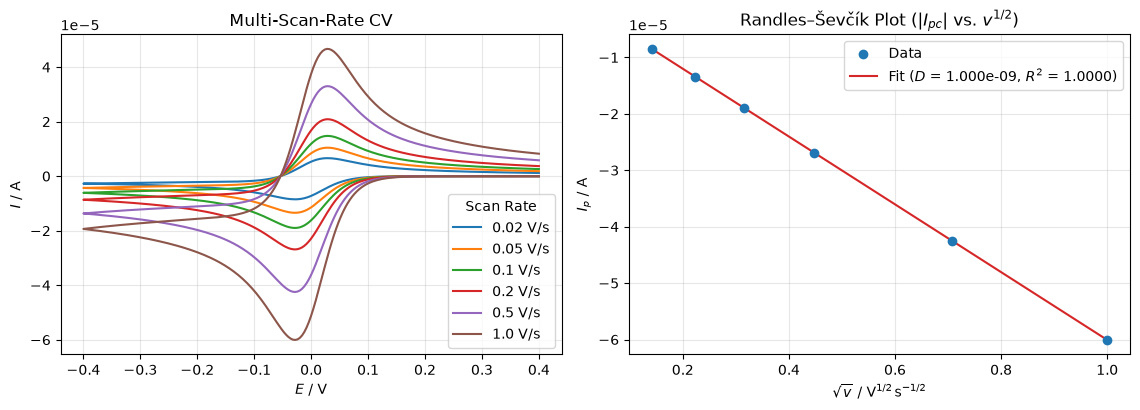

In [3]:
rs_diag = analyze_randles_sevcik(cv_sweep, n=1, area=area, c_bulk=c_bulk)
i_peaks = np.array([abs(res.current.min()) for res in cv_sweep.values()])
fit = spa.fit_randles_sevcik(np.array(scan_rates), i_peaks, n=1, area=area, c_bulk=c_bulk)
ci = fit.confidence_intervals["D"]

print(f"analyze_randles_sevcik -> D = {rs_diag.d:.4e} m^2/s (R^2 = {rs_diag.r_squared:.6f})")
print(f"fit_randles_sevcik     -> D = {fit.params['D']:.4e} m^2/s (95% CI: [{ci[0]:.4e}, {ci[1]:.4e}])")

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
plot_sweep(cv_sweep, ax=axes[0], labels=[f"{v} V/s" for v in scan_rates], legend_title="Scan Rate")
axes[0].set_title("Multi-Scan-Rate CV")

plot_randles_sevcik(cv_sweep, rs_diag, ax=axes[1])
axes[1].set_title("Randles–Ševčík Plot ($|I_{pc}|$ vs. $v^{1/2}$)")

plt.tight_layout()
plt.show()

## 5. Key Takeaways

- For a reversible planar process, $|I_p| = 0.4463\, n F A c^* \sqrt{\frac{n F D v}{RT}}$ scales linearly with $v^{1/2}$.
- `analyze_randles_sevcik()` and `fit_randles_sevcik()` recover $D$ with $R^2 > 0.9999$.
- **Next**: See how finite kinetics affect $\Delta E_p$ in [Butler–Volmer Kinetics & Nicholson Analysis](cv_butler_volmer.ipynb).